In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(
    r"G:/My Drive/Projects/Large projects/2026TexasEnergyFootprint"
)

CLEAN = PROJECT_ROOT / "03_Cleaned_Data"
SPATIAL = PROJECT_ROOT / "04_Spatial_Analysis"


OUTPUT = PROJECT_ROOT / "06_Final_Comparison"
OUTPUT.mkdir(parents=True, exist_ok=True)

# I check that the project folders are available.
assert PROJECT_ROOT.exists(), f"Project folder not found: {PROJECT_ROOT}"
assert CLEAN.exists(), f"Cleaned data folder not found: {CLEAN}"
assert SPATIAL.exists(), f"Spatial analysis folder not found: {SPATIAL}"

print("Project root:", PROJECT_ROOT)
print("Cleaned data:", CLEAN)
print("Spatial analysis:", SPATIAL)
print("Final comparison output:", OUTPUT)
print("Setup complete.")

Project root: G:\My Drive\Projects\Large projects\2026TexasEnergyFootprint
Cleaned data: G:\My Drive\Projects\Large projects\2026TexasEnergyFootprint\03_Cleaned_Data
Spatial analysis: G:\My Drive\Projects\Large projects\2026TexasEnergyFootprint\04_Spatial_Analysis
Final comparison output: G:\My Drive\Projects\Large projects\2026TexasEnergyFootprint\06_Final_Comparison
Setup complete.


In [2]:
# I use the output folders defined in my footprint notebooks.
FOOTPRINT = PROJECT_ROOT / "06_Energy_Footprint_Analysis"

# I load the revised wells and pipeline calculations.
wells_new = pd.read_csv(
    FOOTPRINT / "Wells" / "wells_site_acreage_revised_tony.csv",
    dtype={"county_geoid": "string"}
)

# I load my final pipeline footprint after removing overlapping ROW areas.
pipelines_new = pd.read_csv(
    FOOTPRINT / "Pipelines" / "Pipeline_Unique_ROW"
    / "pipeline_unique_row_county_254.csv",
    dtype={"county_geoid": "string"}
)

# I verify that the new pipeline acreage matches my statewide union result.
assert np.isclose(
    pipelines_new["unique_row_acres"].sum(),
    984144.19,
    atol=0.01,
    rtol=0
)

# I load the final county-level wind, solar and battery results.
wind = pd.read_csv(
    FOOTPRINT / "Wind" / "wind_county_254_with_names.csv",
    dtype={"county_geoid": "string"}
)

solar = pd.read_csv(
    FOOTPRINT / "Solar" / "solar_county_254_with_names.csv",
    dtype={"county_geoid": "string"}
)

battery = pd.read_csv(
    FOOTPRINT / "Battery" / "battery_county_254_with_names.csv",
    dtype={"county_geoid": "string"}
)

# I check the number of records and columns in each dataset.
datasets = {
    "Wells (revised)": wells_new,
    "Pipelines (revised)": pipelines_new,
    "Wind": wind,
    "Solar": solar,
    "Battery": battery
}

for name, data in datasets.items():
    print(f"\n{name}: {len(data):,} records")
    print("Columns:", data.columns.tolist())

print("\nAll five datasets loaded successfully.")


Wells (revised): 436,776 records
Columns: ['site_id', 'county_geoid', 'region', 'well_records', 'horizontal_directional', 'estimated_acres']

Pipelines (revised): 254 records
Columns: ['county_geoid', 'county_name', 'candidate_features', 'unique_row_acres', 'pipeline_miles', 'new_row_acres', 'difference_acres', 'difference_pct']

Wind: 254 records
Columns: ['county_geoid', 'county_name', 'turbines', 'estimated_capacity_turbines', 'capacity_mw', 'wind_acres']

Solar: 254 records
Columns: ['county_geoid', 'county_name', 'unique_acres_recalculated', 'low_acres', 'central_acres', 'high_acres', 'project_polygon_acres', 'project_parts', 'distinct_projects']

Battery: 254 records
Columns: ['county_geoid', 'county_name', 'plants', 'capacity_mw', 'low_acres', 'central_acres', 'high_acres', 'indiana_low_acres', 'indiana_high_acres', 'naco_low_acres', 'naco_high_acres']

All five datasets loaded successfully.


In [3]:
#  Aggregate revised well-site acreage by county

# I standardize county identifiers before aggregation.
wells_new["county_geoid"] = (
    wells_new["county_geoid"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

# I use the pipeline county table as the reference for all 254 counties.
texas_counties = (
    pipelines_new[["county_geoid", "county_name"]]
    .drop_duplicates()
    .copy()
)

# I check which well sites have no valid Texas county assignment.
valid_counties = set(texas_counties["county_geoid"])

wells_new["valid_county"] = wells_new["county_geoid"].isin(
    valid_counties
)

unassigned_wells = wells_new.loc[
    ~wells_new["valid_county"]
].copy()

print("Total well sites:", f"{len(wells_new):,}")
print("Sites assigned to Texas counties:",
      f"{wells_new['valid_county'].sum():,}")
print("Sites without valid county:",
      f"{len(unassigned_wells):,}")

print(
    "Unassigned site acreage:",
    f"{unassigned_wells['estimated_acres'].sum():,.2f}"
)

# I calculate county totals using only valid county assignments.
wells_county = (
    wells_new.loc[wells_new["valid_county"]]
    .groupby("county_geoid", as_index=False)
    .agg(
        potential_sites=("site_id", "size"),
        well_records=("well_records", "sum"),
        wells_acres=("estimated_acres", "sum")
    )
)

# I retain all 254 Texas counties, including those with zero well sites.
wells_county_254 = texas_counties.merge(
    wells_county,
    on="county_geoid",
    how="left",
    validate="one_to_one"
)

wells_county_254[
    ["potential_sites", "well_records", "wells_acres"]
] = wells_county_254[
    ["potential_sites", "well_records", "wells_acres"]
].fillna(0)

# I verify that the county and unassigned totals reconcile.
statewide_wells_acres = wells_new["estimated_acres"].sum()
county_wells_acres = wells_county_254["wells_acres"].sum()
unassigned_acres = unassigned_wells["estimated_acres"].sum()

assert len(wells_county_254) == 254

assert np.isclose(
    county_wells_acres + unassigned_acres,
    statewide_wells_acres,
    atol=0.01,
    rtol=0
)

assert (
    wells_county_254["potential_sites"].sum()
    + len(unassigned_wells)
    == len(wells_new)
)

print("\nRevised wells footprint:")
print("County-assigned acreage:", f"{county_wells_acres:,.2f}")
print("Unassigned acreage:", f"{unassigned_acres:,.2f}")
print("Statewide acreage:", f"{statewide_wells_acres:,.2f}")

display(wells_county_254.head())

Total well sites: 436,776
Sites assigned to Texas counties: 436,235
Sites without valid county: 541
Unassigned site acreage: 633.99

Revised wells footprint:
County-assigned acreage: 657,689.62
Unassigned acreage: 633.99
Statewide acreage: 658,323.60


,county_geoid,county_name,potential_sites,well_records,wells_acres
0,48001,Anderson,1327.0,1348.0,1219.500000
1,48003,Andrews,12981.0,14024.0,12060.857838
2,48005,Angelina,190.0,263.0,211.800000
3,48007,Aransas,451.0,484.0,453.300000
4,48009,Archer,7471.0,7471.0,19424.600000


In [4]:
# I calculate statewide acreage using the final estimates.
statewide_comparison = pd.DataFrame([
    {
        "energy_type": "Wells",
        "category": "Fossil fuel",
        "estimated_acres": wells_new["estimated_acres"].sum()
    },
    {
        "energy_type": "Pipelines",
        "category": "Fossil fuel",
        "estimated_acres": pipelines_new["unique_row_acres"].sum()
    },
    {
        "energy_type": "Wind",
        "category": "Renewable",
        "estimated_acres": wind["wind_acres"].sum()
    },
    {
        "energy_type": "Solar",
        "category": "Renewable",
        "estimated_acres": solar["central_acres"].sum()
    },
    {
        "energy_type": "Battery",
        "category": "Energy storage",
        "estimated_acres": battery["central_acres"].sum()
    }
])

# I calculate each energy type's share of the combined estimate.
statewide_comparison["share_pct"] = (
    statewide_comparison["estimated_acres"]
    / statewide_comparison["estimated_acres"].sum()
    * 100
)

# I sort the results by estimated acreage.
statewide_comparison = (
    statewide_comparison
    .sort_values("estimated_acres", ascending=False)
    .reset_index(drop=True)
)

display(statewide_comparison.round(2))

# I summarize the results by energy category.
category_comparison = (
    statewide_comparison.groupby("category", as_index=False)
    .agg(estimated_acres=("estimated_acres", "sum"))
    .sort_values("estimated_acres", ascending=False)
)

display(category_comparison.round(2))

print(
    "Combined estimated footprint:",
    f"{statewide_comparison['estimated_acres'].sum():,.2f} acres"
)

,energy_type,category,estimated_acres,share_pct
0,Pipelines,Fossil fuel,984144.19,52.91
1,Wells,Fossil fuel,658323.60,35.39
2,Solar,Renewable,143025.17,7.69
3,Wind,Renewable,73168.42,3.93
4,Battery,Energy storage,1390.93,0.07


,category,estimated_acres
1,Fossil fuel,1642467.80
2,Renewable,216193.59
0,Energy storage,1390.93


Combined estimated footprint: 1,860,052.32 acres


In [5]:
# I start with the 254 Texas counties.
county_comparison = (
    texas_counties[["county_geoid", "county_name"]]
    .drop_duplicates()
    .copy()
)

# I combine the county-level acreage from all five energy types.
energy_inputs = [
    (wells_county_254, "wells_acres", "wells_acres"),
    (pipelines_new, "unique_row_acres", "pipelines_acres"),
    (wind, "wind_acres", "wind_acres"),
    (solar, "central_acres", "solar_acres"),
    (battery, "central_acres", "battery_acres")
]

for data, source_col, output_col in energy_inputs:
    county_comparison = county_comparison.merge(
        data[["county_geoid", source_col]].rename(
            columns={source_col: output_col}
        ),
        on="county_geoid",
        how="left",
        validate="one_to_one"
    )

# I fill missing acreage values with zero.
acreage_cols = [
    "wells_acres",
    "pipelines_acres",
    "wind_acres",
    "solar_acres",
    "battery_acres"
]

county_comparison[acreage_cols] = (
    county_comparison[acreage_cols].fillna(0)
)

# I calculate fossil fuel, renewable and combined acreage.
county_comparison["fossil_fuel_acres"] = (
    county_comparison["wells_acres"]
    + county_comparison["pipelines_acres"]
)

county_comparison["renewable_acres"] = (
    county_comparison["wind_acres"]
    + county_comparison["solar_acres"]
)

county_comparison["combined_acres"] = (
    county_comparison["fossil_fuel_acres"]
    + county_comparison["renewable_acres"]
    + county_comparison["battery_acres"]
)

# I check that every county appears exactly once.
assert len(county_comparison) == 254
assert county_comparison["county_geoid"].is_unique

# I verify that county totals match their input datasets.
assert np.isclose(
    county_comparison["wells_acres"].sum(),
    county_wells_acres,
    atol=0.01
)

assert np.isclose(
   county_comparison["pipelines_acres"].sum(),
pipelines_new["unique_row_acres"].sum(),
    atol=0.01
)

for source, column, output in [
    (wind, "wind_acres", "wind_acres"),
    (solar, "central_acres", "solar_acres"),
    (battery, "central_acres", "battery_acres")
]:
    assert np.isclose(
        county_comparison[output].sum(),
        source[column].sum(),
        atol=0.01
    )

# I display the counties with the largest combined estimates.
display(
    county_comparison.sort_values(
        "combined_acres", ascending=False
    ).head(15).round(2)
)

print("Counties:", len(county_comparison))
print(
    "County-assigned combined acreage:",
    f"{county_comparison['combined_acres'].sum():,.2f}"
)
print(
    "Unassigned wells acreage:",
    f"{unassigned_acres:,.2f}"
)
print(
    "Statewide combined acreage:",
    f"{statewide_comparison['estimated_acres'].sum():,.2f}"
)

,county_geoid,county_name,wells_acres,pipelines_acres,wind_acres,solar_acres,battery_acres,fossil_fuel_acres,renewable_acres,combined_acres
239,48479,Webb,19308.25,15311.99,1378.73,1544.66,37.87,34620.24,2923.39,37581.50
242,48485,Wichita,36069.10,1359.73,0.00,0.00,0.00,37428.83,0.00,37428.83
185,48371,Pecos,6465.98,15473.53,1108.56,12610.23,83.00,21939.51,13718.78,35741.29
1,48003,Andrews,12060.86,14577.31,258.18,7202.80,4.00,26638.17,7460.98,34103.15
194,48389,Reeves,5163.10,26124.68,0.00,0.00,49.07,31287.78,0.00,31336.85
230,48461,Upton,6149.82,16296.90,1212.00,4405.92,13.65,22446.72,5617.92,28078.29
164,48329,Midland,6108.01,20866.58,225.16,0.00,0.00,26974.59,225.16,27199.75
248,48497,Wise,12623.00,12331.52,0.00,159.90,12.50,24954.52,159.90,25126.92
141,48283,La Salle,13607.51,10711.53,0.00,0.00,0.99,24319.04,0.00,24320.03
158,48317,Martin,5780.03,18057.91,192.74,0.00,0.00,23837.94,192.74,24030.69


Counties: 254
County-assigned combined acreage: 1,859,418.33
Unassigned wells acreage: 633.99
Statewide combined acreage: 1,860,052.32


In [6]:
# I verify that the county totals reconcile with the statewide results.
assert np.isclose(
    county_comparison["combined_acres"].sum() + unassigned_acres,
    statewide_comparison["estimated_acres"].sum(),
    atol=0.02,
    rtol=0
)

# I keep county GEOIDs as five-character identifiers.
county_comparison["county_geoid"] = (
    county_comparison["county_geoid"]
    .astype("string")
    .str.zfill(5)
)

# I save the final statewide comparison.
statewide_comparison.to_csv(
    OUTPUT / "texas_energy_footprint_statewide_final.csv",
    index=False
)

# I save the county comparison with all 254 counties.
county_comparison.to_csv(
    OUTPUT / "texas_energy_footprint_county_254_final.csv",
    index=False
)

# I save the category totals separately.
category_comparison.to_csv(
    OUTPUT / "texas_energy_footprint_category_final.csv",
    index=False
)

# I document the unassigned wells separately.
unassigned_wells.to_csv(
    OUTPUT / "texas_wells_unassigned_county_final.csv",
    index=False
)

print("Final comparison files saved to:", OUTPUT)
print("Counties:", len(county_comparison))
print("Statewide acreage:", f"{statewide_comparison['estimated_acres'].sum():,.2f}")
print("County-assigned acreage:", f"{county_comparison['combined_acres'].sum():,.2f}")
print("Unassigned wells acreage:", f"{unassigned_acres:,.2f}")

Final comparison files saved to: G:\My Drive\Projects\Large projects\2026TexasEnergyFootprint\06_Final_Comparison
Counties: 254
Statewide acreage: 1,860,052.32
County-assigned acreage: 1,859,418.33
Unassigned wells acreage: 633.99


Lato is not installed. Matplotlib will use its default font.


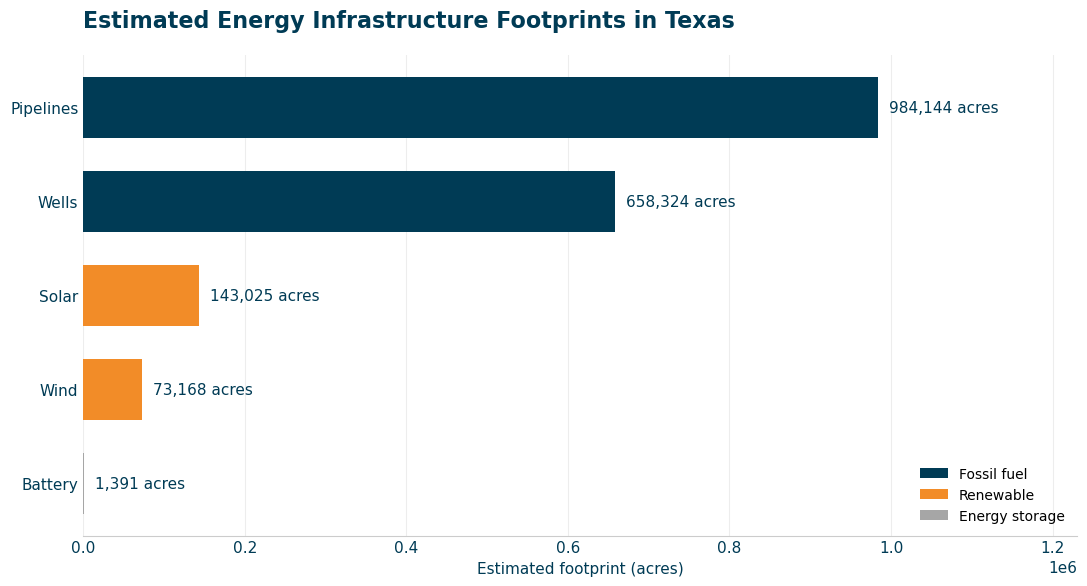

In [7]:
from matplotlib import font_manager
from matplotlib.patches import Patch

# I use Lato for all figures when the font is installed.
available_fonts = {font.name for font in font_manager.fontManager.ttflist}

if "Lato" in available_fonts:
    plt.rcParams["font.family"] = "Lato"
else:
    print("Lato is not installed. Matplotlib will use its default font.")

# I define Frontier Group's colors.
FRONTIER = {
    "navy": "#003B55",
    "dark": "#002169",
    "lime": "#C2D500",
    "green": "#75AE4F",
    "white": "#FFFFFF"
}

plt.rcParams.update({
    "figure.facecolor": FRONTIER["white"],
    "axes.facecolor": FRONTIER["white"],
    "savefig.facecolor": FRONTIER["white"],
    "font.size": 11,
    "axes.titlesize": 16,
    "axes.labelsize": 11
})

# I assign consistent colors to each energy category.
category_colors = {
    "Fossil fuel": "#003B55",
    "Renewable": "#F28C28",
    "Energy storage": "#A6A6A6"
}
chart_data = statewide_comparison.sort_values(
    "estimated_acres",
    ascending=True
).copy()

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    chart_data["energy_type"],
    chart_data["estimated_acres"],
    color=chart_data["category"].map(category_colors),
    height=0.65
)

# I add acreage labels beside each bar.
for bar, acres in zip(bars, chart_data["estimated_acres"]):
    ax.annotate(
        f"{acres:,.0f} acres",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(8, 0),
        textcoords="offset points",
        va="center",
        fontsize=11,
        color=FRONTIER["navy"]
    )

ax.set_title(
    "Estimated Energy Infrastructure Footprints in Texas",
    loc="left",
    weight="bold",
    color=FRONTIER["navy"],
    pad=20
)

ax.set_xlabel("Estimated footprint (acres)", color=FRONTIER["navy"])
ax.set_ylabel("")

ax.set_xlim(0, chart_data["estimated_acres"].max() * 1.25)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#CCCCCC")

ax.tick_params(axis="both", length=0, colors=FRONTIER["navy"])
ax.grid(axis="x", color="#DDDDDD", alpha=0.5)
ax.set_axisbelow(True)

# I add a legend using the same category colors.
legend_items = [
    Patch(facecolor=category_colors[name], label=name)
    for name in ["Fossil fuel", "Renewable", "Energy storage"]
]

ax.legend(
    handles=legend_items,
    loc="lower right",
    frameon=False,
    fontsize=10
)

fig.tight_layout()

# I save the branded chart.
fig.savefig(
    OUTPUT / "texas_energy_footprint_statewide_frontier.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
# I reuse the county boundaries from Notebook 02.
county_candidates = [
    PROJECT_ROOT / "01_Raw_Data" / "Texas_Boundaries" / "tl_2026_us_county",
    PROJECT_ROOT / "Texas Boundries" / "tl_2026_us_county"
]

county_source = next(
    (path for path in county_candidates if path.exists()),
    None
)

if county_source is None:
    raise FileNotFoundError(
        f"County boundaries not found: {county_candidates}"
    )

# I load the Census county boundaries and select Texas.
us_counties = gpd.read_file(county_source)

texas_map = us_counties.loc[
    us_counties["STATEFP"].astype(str).str.zfill(2).eq("48")
].copy()

# I use the same projected coordinate system as Notebook 02.
texas_map = texas_map.to_crs("EPSG:3083")

# I standardize county identifiers.
texas_map["county_geoid"] = (
    texas_map["GEOID"]
    .astype("string")
    .str.zfill(5)
)

# I join the county boundaries to the final footprint results.
texas_map = texas_map.merge(
    county_comparison.drop(columns="county_name"),
    on="county_geoid",
    how="left",
    validate="one_to_one"
)

# I check that all 254 counties have matching data.
assert len(texas_map) == 254
assert texas_map["county_geoid"].is_unique
assert texas_map["combined_acres"].notna().all()

print("County boundary source:", county_source)
print("Texas counties:", len(texas_map))
print("Coordinate system:", texas_map.crs)
print(
    "Mapped acreage:",
    f"{texas_map['combined_acres'].sum():,.2f}"
)

print("County map prepared successfully.")

County boundary source: G:\My Drive\Projects\Large projects\2026TexasEnergyFootprint\01_Raw_Data\Texas_Boundaries\tl_2026_us_county
Texas counties: 254
Coordinate system: EPSG:3083
Mapped acreage: 1,859,418.33
County map prepared successfully.


In [9]:
from pathlib import Path
from matplotlib import font_manager
import matplotlib.pyplot as plt
import os

font_folders = [
    Path("C:/Windows/Fonts"),
    Path.home() / "AppData/Local/Microsoft/Windows/Fonts"
]

lato_files = [
    path
    for folder in font_folders
    if folder.exists()
    for path in folder.glob("*.ttf")
    if "lato" in path.name.lower()
]

for path in lato_files:
    font_manager.fontManager.addfont(str(path))

available_lato = sorted({
    font_manager.FontProperties(fname=str(path)).get_name()
    for path in lato_files
})

print("Lato font files found:", len(lato_files))
print("Available Lato fonts:", available_lato)

if "Lato" in available_lato:
    plt.rcParams["font.family"] = "Lato"
    print("Lato is ready.")
else:
    plt.rcParams["font.family"] = "DejaVu Sans"
    print("Lato not found. Install Lato on Windows and rerun this cell.")

Lato font files found: 10
Available Lato fonts: ['Lato']
Lato is ready.


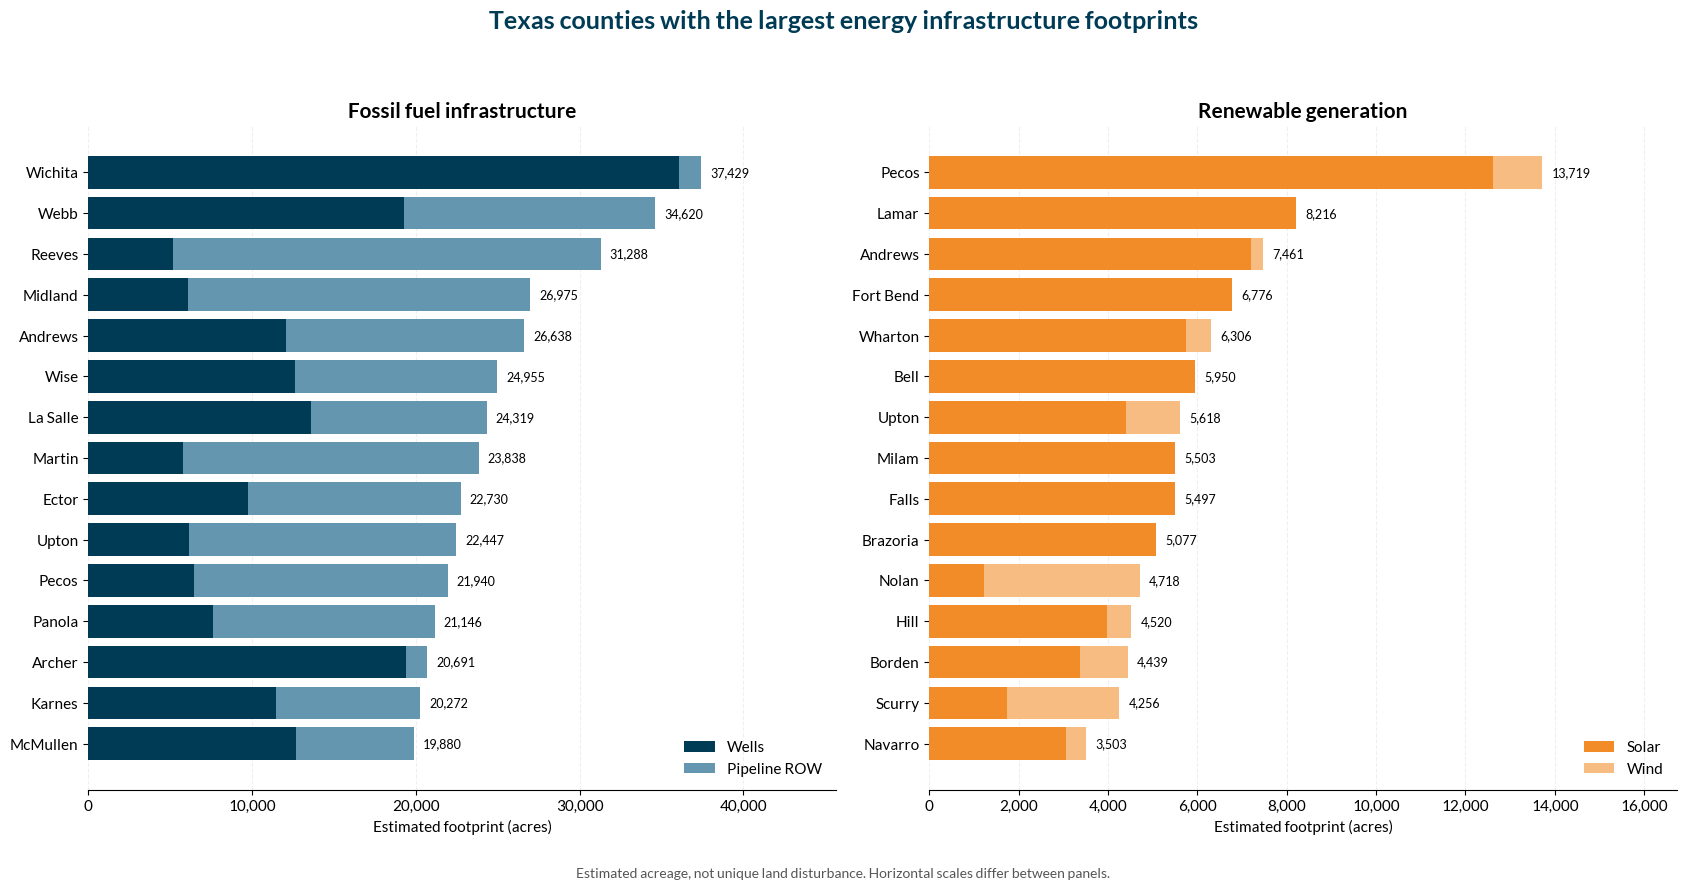

Top 15 county charts and CSV files saved.


In [10]:
from matplotlib.ticker import FuncFormatter

# I use Lato and the blue and orange colors selected for this report.
plt.rcParams["font.family"] = "Lato"

# I identify the 15 counties with the largest footprints in each category.
top_fossil = (
    county_comparison
    .nlargest(15, "fossil_fuel_acres")
    .sort_values("fossil_fuel_acres")
)

top_renewable = (
    county_comparison
    .nlargest(15, "renewable_acres")
    .sort_values("renewable_acres")
)

fig, axes = plt.subplots(1, 2, figsize=(17, 9))

# I use stacked bars to distinguish wells from pipelines.
axes[0].barh(
    top_fossil["county_name"],
    top_fossil["wells_acres"],
    color="#003B55",
    label="Wells"
)

axes[0].barh(
    top_fossil["county_name"],
    top_fossil["pipelines_acres"],
    left=top_fossil["wells_acres"],
    color="#6596B0",
    label="Pipeline ROW"
)

axes[0].set_title(
    "Fossil fuel infrastructure",
    fontsize=15,
    weight="bold"
)

# I use stacked bars to distinguish solar from wind.
axes[1].barh(
    top_renewable["county_name"],
    top_renewable["solar_acres"],
    color="#F28C28",
    label="Solar"
)

axes[1].barh(
    top_renewable["county_name"],
    top_renewable["wind_acres"],
    left=top_renewable["solar_acres"],
    color="#F6BC82",
    label="Wind"
)

axes[1].set_title(
    "Renewable generation",
    fontsize=15,
    weight="bold"
)

# I use separate horizontal scales and label the total acreage.
for ax, data, total_col in [
    (axes[0], top_fossil, "fossil_fuel_acres"),
    (axes[1], top_renewable, "renewable_acres")
]:
    max_acres = data[total_col].max()

    ax.set_xlim(0, max_acres * 1.22)
    ax.set_xlabel("Estimated footprint (acres)")

    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: f"{x:,.0f}")
    )

    ax.grid(axis="x", alpha=0.2, linestyle="--")
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)

    ax.legend(loc="lower right", frameon=False)

    for i, acres in enumerate(data[total_col]):
        ax.text(
            acres + max_acres * 0.015,
            i,
            f"{acres:,.0f}",
            va="center",
            fontsize=9
        )

fig.suptitle(
    "Texas counties with the largest energy infrastructure footprints",
    fontsize=18,
    weight="bold",
    color="#003B55",
    y=0.99
)

fig.text(
    0.5, 0.025,
    "Estimated acreage, not unique land disturbance. "
    "Horizontal scales differ between panels.",
    ha="center",
    fontsize=10,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.055, 1, 0.95])

# I save the charts in PNG and SVG formats.
fig.savefig(
    OUTPUT / "top_15_counties_energy_footprint.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT / "top_15_counties_energy_footprint.svg",
    bbox_inches="tight"
)

plt.show()

# I save the rankings for future visualizations.
top_fossil.sort_values(
    "fossil_fuel_acres", ascending=False
).to_csv(
    OUTPUT / "top_15_fossil_counties.csv",
    index=False
)

top_renewable.sort_values(
    "renewable_acres", ascending=False
).to_csv(
    OUTPUT / "top_15_renewable_counties.csv",
    index=False
)

print("Top 15 county charts and CSV files saved.")


Top 15 counties for Solar:
county_name  solar_acres
      Pecos 12610.225809
      Lamar  8215.966365
    Andrews  7202.802984
  Fort Bend  6776.132964
       Bell  5949.864218
    Wharton  5747.786676
      Milam  5502.674257
      Falls  5497.358452
   Brazoria  5077.387692
      Upton  4405.915685
       Hill  3971.715629
     Borden  3374.937256
  Tom Green  3127.628596
    Navarro  3060.980566
  Culberson  3002.393889

Top 15 counties for Wind:
 county_name  wind_acres
       Nolan 3493.805691
     Willacy 2710.726266
      Scurry 2513.816019
    Crockett 2410.273304
Throckmorton 2122.236152
    Sterling 1950.808029
   Glasscock 1784.086028
      Kenedy 1737.892148
      Carson 1715.485867
       Starr 1713.156899
    Hansford 1694.589401
       Floyd 1635.626350
        Knox 1579.618680
San Patricio 1570.334931
    Callahan 1453.340417

Top 15 counties for Battery storage:
county_name  battery_acres
   Brazoria          95.15
      Pecos          83.00
    Hopkins          67.58

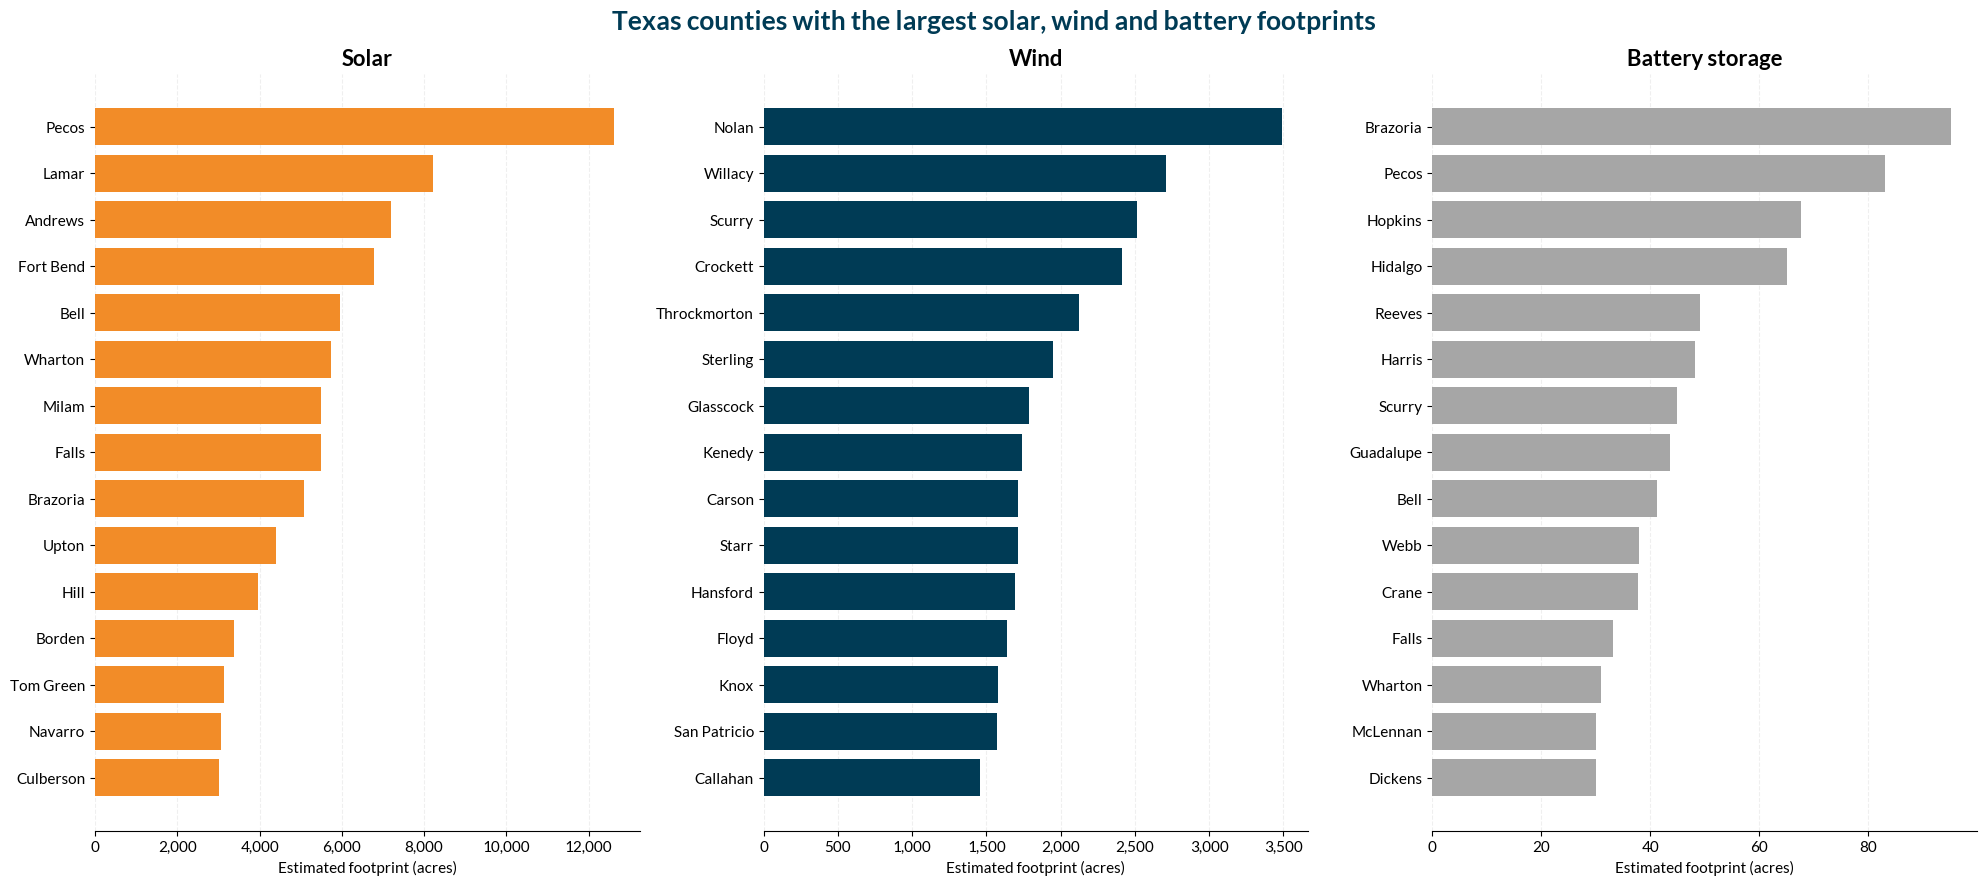

In [11]:
# I examine each technology separately to identify its geographic concentration.
technologies = [
    ("solar_acres", "Solar", "#F28C28"),
    ("wind_acres", "Wind", "#003B55"),
    ("battery_acres", "Battery storage", "#A6A6A6")
]

fig, axes = plt.subplots(1, 3, figsize=(20, 9))

for ax, (column, title, color) in zip(axes, technologies):

    # I select the counties with the largest estimated acreage.
    top_15 = (
        county_comparison
        .nlargest(15, column)
        .sort_values(column)
    )

    ax.barh(
        top_15["county_name"],
        top_15[column],
        color=color
    )

    ax.set_title(title, fontsize=16, fontweight="bold")
    ax.set_xlabel("Estimated footprint (acres)")

    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: f"{x:,.0f}")
    )

    ax.grid(axis="x", linestyle="--", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)

    print(f"\nTop 15 counties for {title}:")
    print(
        top_15[["county_name", column]]
        .sort_values(column, ascending=False)
        .to_string(index=False)
    )

fig.suptitle(
    "Texas counties with the largest solar, wind and battery footprints",
    fontsize=19,
    fontweight="bold",
    color="#003B55"
)

plt.tight_layout()

# I save the technology-specific comparison chart.
fig.savefig(
    OUTPUT / "top_15_counties_solar_wind_battery.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


Top 15 counties for Solar:
county_name  solar_acres
      Pecos 12610.225809
      Lamar  8215.966365
    Andrews  7202.802984
  Fort Bend  6776.132964
       Bell  5949.864218
    Wharton  5747.786676
      Milam  5502.674257
      Falls  5497.358452
   Brazoria  5077.387692
      Upton  4405.915685
       Hill  3971.715629
     Borden  3374.937256
  Tom Green  3127.628596
    Navarro  3060.980566
  Culberson  3002.393889

Top 15 counties for Wind:
 county_name  wind_acres
       Nolan 3493.805691
     Willacy 2710.726266
      Scurry 2513.816019
    Crockett 2410.273304
Throckmorton 2122.236152
    Sterling 1950.808029
   Glasscock 1784.086028
      Kenedy 1737.892148
      Carson 1715.485867
       Starr 1713.156899
    Hansford 1694.589401
       Floyd 1635.626350
        Knox 1579.618680
San Patricio 1570.334931
    Callahan 1453.340417

Top 15 counties for Battery storage:
county_name  battery_acres
   Brazoria          95.15
      Pecos          83.00
    Hopkins          67.58

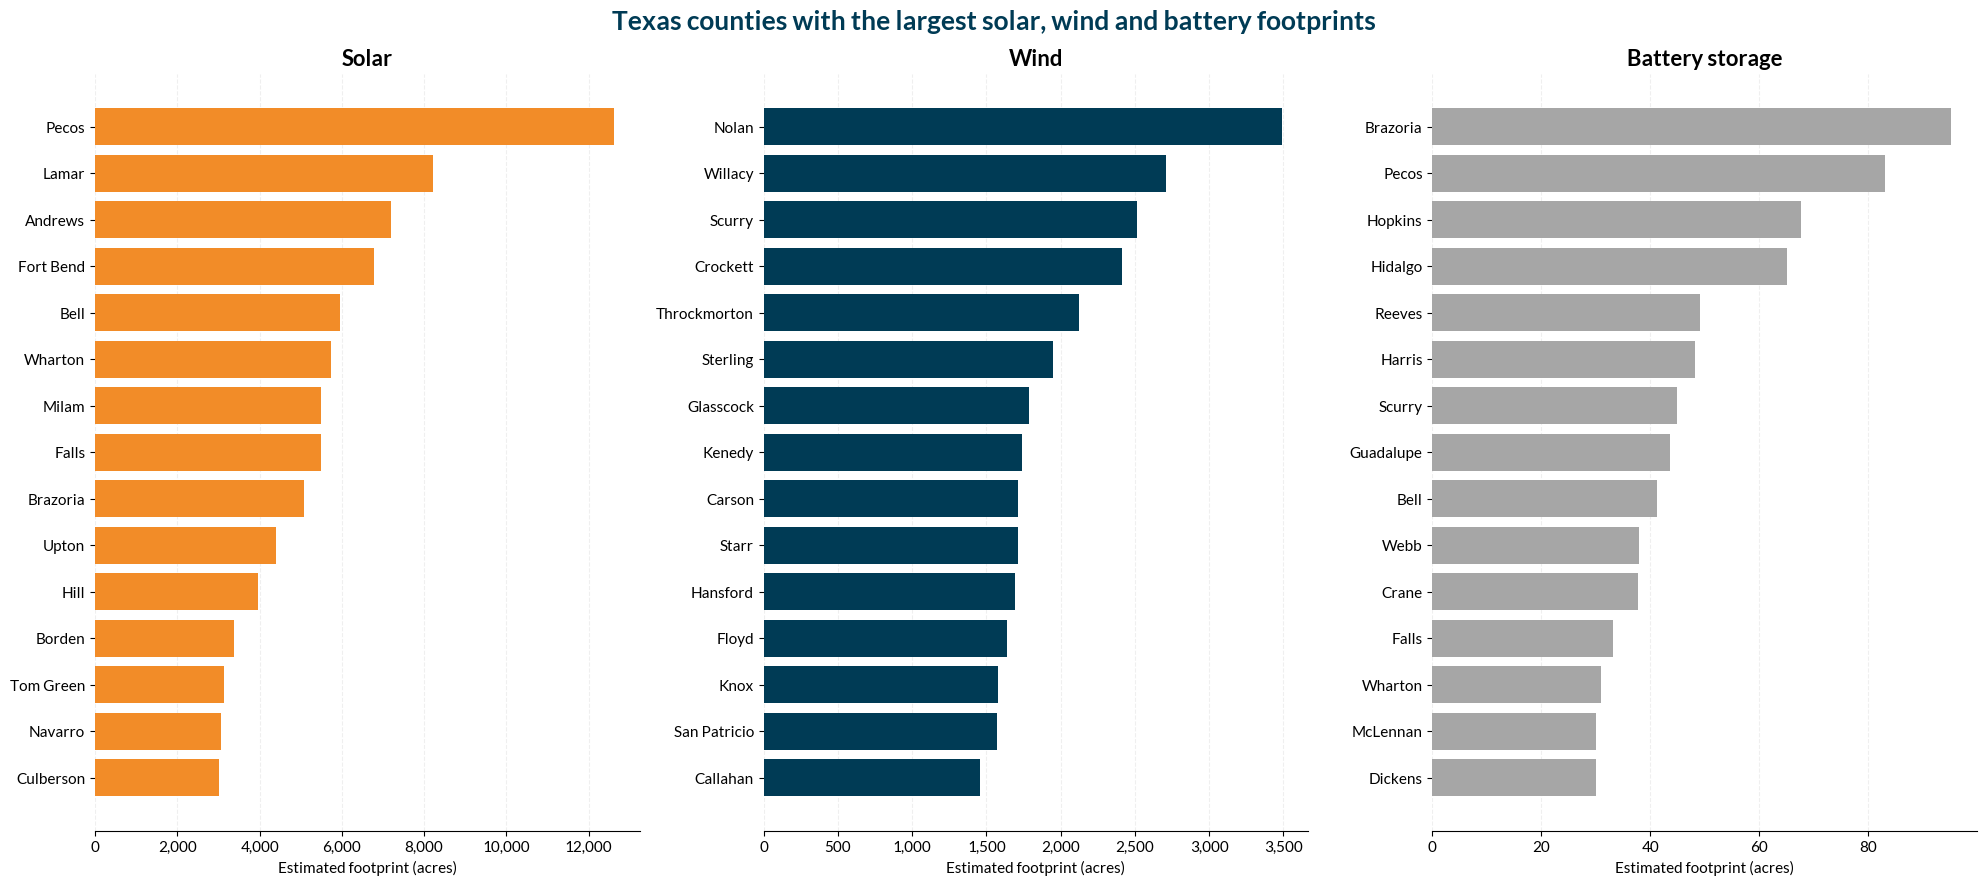

In [12]:
# I examine each technology separately to identify its geographic concentration.
technologies = [
    ("solar_acres", "Solar", "#F28C28"),
    ("wind_acres", "Wind", "#003B55"),
    ("battery_acres", "Battery storage", "#A6A6A6")
]

fig, axes = plt.subplots(1, 3, figsize=(20, 9))

for ax, (column, title, color) in zip(axes, technologies):

    # I select the counties with the largest estimated acreage.
    top_15 = (
        county_comparison
        .nlargest(15, column)
        .sort_values(column)
    )

    ax.barh(
        top_15["county_name"],
        top_15[column],
        color=color
    )

    ax.set_title(title, fontsize=16, fontweight="bold")
    ax.set_xlabel("Estimated footprint (acres)")

    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: f"{x:,.0f}")
    )

    ax.grid(axis="x", linestyle="--", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)

    print(f"\nTop 15 counties for {title}:")
    print(
        top_15[["county_name", column]]
        .sort_values(column, ascending=False)
        .to_string(index=False)
    )

fig.suptitle(
    "Texas counties with the largest solar, wind and battery footprints",
    fontsize=19,
    fontweight="bold",
    color="#003B55"
)

plt.tight_layout()

# I save the technology-specific comparison chart.
fig.savefig(
    OUTPUT / "top_15_counties_solar_wind_battery.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()